# 03 — Metodologia: desenho, regras, validação, métricas e incerteza

Atualiza `Relatórios do Projeto/03_METODOLOGIA.md` (outubro/2026). Pressupõe os notebooks 01 e 02. Todos os
números estão no notebook `abandono-escolar/notebooks/03_avaliacao` e na síntese (§3); aqui fica o método,
com as figuras principais.

## O que mudou desde o relatório de outubro

| Tema | Relatório 03 (14/10/2026) | Agora | Registro |
|---|---|---|---|
| Objetivo do método | prever a taxa e escolher o melhor modelo | medir **qual bloco de informação** carrega sinal; a previsão é o instrumento | `DECISOES.md` 2026-11-02 |
| Preditores | tudo de *t*, inclusive o abandono de *t*, o trio de rendimento e o IED N1–N6 + ALTO | **Cenário B:** sem rendimento de *t*; abandono e reprovação de *t*−1 e variação defasada; nunca o trio; IED só N1..N5 | P026; Etapa 2 |
| Vazamento | temporal e entre alvos | + a **reconstrução**: `DELTA1` + lag = abandono de *t* | Etapa 2 |
| Pico de 2022 (opções A/B/C) | em aberto | decidido: 2020–2021 ficam, com sensibilidade S1–S4 (D6); 2022 não é pico no AF | D6; síntese §4 #2 |
| Split (A/B/C) | em aberto | **walk-forward** com janela expansiva, testes 2021–2024; 2024→2025 bloqueado (D7) | D7; Etapa 2 |
| Baseline | "persistência: MAE ≈ 2,5" (esperado) | **medido:** B0, B1, B1R, B2 e **B1R_lag**, a barra principal | Etapa 1; `DECISOES.md` |
| Modelos | Ridge, Random Forest e HistGradientBoosting, com One-Hot do município | **Ridge (α = 1) e árvore (profundidade 3, ≥ 20 por folha)**, fixos e sem ajuste; Random Forest e boosting não rodados | Etapa 2 |
| Métricas | Recall@K como principal, junto com MAE, RMSE e R² | **só o Recall@K decide**, com K = 10% e 20% das escolas do ano; R² e MAE só descrevem | Etapa 1 e 2 |
| Incerteza | não tratada | **bootstrap por escola**, IC 95%, **Holm** por família declarada antes de rodar | regra de testes múltiplos |
| Importância | por coluna (impureza) | por **permutação de grupo** inteiro | P026 |
| Os 4 problemas do `v1.ipynb` | "corrigir" | o notebook foi substituído pelo protocolo em `gustavo/avaliacao/` (doc 06, D16) | síntese §6.2 |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
sys.path.insert(0, str(GUSTAVO / "avaliacao"))
import painel                                   # gustavo/avaliacao/painel.py: blocos e cenários (só definições)
import walkforward                              # ANOS_TESTE

ENTRADAS = {
    "cobertura": OFICIAL / "docs" / "desfechos_cobertura.csv",            # python -m src.analise_base_longitudinal
    "familias": TABELAS / "familias_holm.csv",                            # gerar_tabelas.py
    "sintese": GUSTAVO / "saida" / "avaliacao" / "sintese_numeros.csv",   # gustavo/avaliacao/sintese_numeros.py
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"; os demais pelo script do comentário')
cobertura = pd.read_csv(ENTRADAS["cobertura"])
familias = pd.read_csv(ENTRADAS["familias"])
sintese = pd.read_csv(ENTRADAS["sintese"])
print("anos de teste do walk-forward (ANO_ALVO):", walkforward.ANOS_TESTE)
print("anos do painel (ANO = t):", list(painel.ANOS_FEATURES))

anos de teste do walk-forward (ANO_ALVO): (2021, 2022, 2023, 2024)
anos do painel (ANO = t): [2019, 2020, 2021, 2022, 2023, 2024]


# Parte A — Desenho

## 1. A unidade, o desenho *t* → *t*+1 e os dois painéis

- **Unidade:** escola-ano (D1); o desfecho é uma taxa agregada de 0 a 100.
- **Desenho:** informação do ano *t* (ou anterior) → **abandono da etapa em *t*+1** (D4). Nunca informação
  de *t*+1 como preditor (regra 4).
- **Dois painéis** (D2): AF, com o desfecho `ABANDONO_FUN_AF_T1`, e EM, com `ABANDONO_MED_T1`. Cada modelo só
  vê variáveis da sua etapa (doc 06, D15). Exceção registrada: no AF o IED é o `IED_FUN` (fundamental
  inteiro), porque a base oficial só tem FUN e MED.
- **Universo de cada painel:** escolas públicas (D3) com o desfecho de *t*+1, ou seja, que oferecem a etapa
  em *t*+1. A escola sem a taxa de *t* fica: no B1 recebe o B0. Assim todos os baselines são avaliados nas
  mesmas escolas.

Tamanho dos painéis por ano (`docs/desfechos_cobertura.csv`):

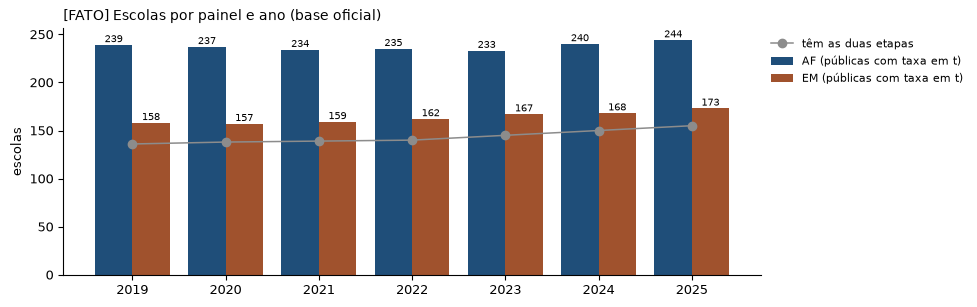

In [3]:
c = cobertura.set_index("ANO")
fig, ax = plt.subplots(figsize=(9, 3.2))
x = c.index.to_numpy()
ax.bar(x - 0.2, c["com_AF"], width=0.4, color=D.AZUL, label="AF (públicas com taxa em t)")
ax.bar(x + 0.2, c["com_EM"], width=0.4, color="#a0522d", label="EM (públicas com taxa em t)")
ax.plot(x, c["AF_e_EM"], color=D.CINZA, marker="o", linewidth=1.1, label="têm as duas etapas")
for xi, a, e in zip(x, c["com_AF"], c["com_EM"]):
    ax.annotate(f"{a}", (xi - 0.2, a), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7)
    ax.annotate(f"{e}", (xi + 0.2, e), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7)
ax.set_ylabel("escolas")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
F.titulo(ax, "Escolas por painel e ano (base oficial)", "FATO")
F.salvar(fig, FIGURAS, "03_paineis_por_ano")
plt.show()

Cerca de 235 escolas no AF e 165 no EM por ano, e cerca de 140 nas duas. Com K = 10%, o Recall@10% do EM
depende de 16 ou 17 escolas: **uma escola muda o resultado em ~0,06**. Esse tamanho explica boa parte da
incerteza da Parte C.

## 2. O que entra no modelo: cenários e blocos

O abandono de *t* só é publicado durante *t*+1: o de 2025 entrou no projeto em 09/09/2026. Na hora de
priorizar as escolas, no início de *t*+1, a Secretaria tem o abandono de *t*−1. Daí os dois cenários:

- **Cenário B (principal):** sem nenhuma taxa de rendimento de *t*. Usa o abandono e a reprovação de *t*−1 e
  a **variação defasada**, abandono(*t*−1) − abandono(*t*−2).
- **Cenário A (teto otimista):** com o rendimento de *t*. Com o abandono de *t* como preditor, a resposta
  seria "o abandono", que é circular.

As colunas abaixo são lidas do próprio código da avaliação (`painel.blocos`). Os blocos são **cumulativos**
e foram fixados antes de rodar: o modelo do bloco *k* usa os blocos 1 a *k*.

In [4]:
linhas = []
for etapa in ("AF", "EM"):
    for cenario in ("B", "A"):
        for k, nome in enumerate(painel.ORDEM_BLOCOS, start=1):
            linhas.append({"etapa": etapa, "cenário": cenario, "bloco": f"{k}. {nome}",
                           "colunas": ", ".join(painel.blocos(etapa, cenario)[nome])})
blocos = pd.DataFrame(linhas)
blocos[blocos["cenário"] == "B"].pivot(index="bloco", columns="etapa", values="colunas")

etapa,AF,EM
bloco,,
1. rendimento,"ABANDONO_FUN_AF_L1, REPROVACAO_FUN_AF_L1, ABANDONO_FUN_AF_DLAG","ABANDONO_MED_L1, REPROVACAO_MED_L1, ABANDONO_MED_DLAG"
2. TDI_ATU,"TDI_FUN_AF, ATU_FUN_AF","TDI_MED_TOTAL, ATU_MED_TOTAL"
3. IED,"IED_FUN_N1, IED_FUN_N2, IED_FUN_N3, IED_FUN_N4, IED_FUN_N5","IED_MED_N1, IED_MED_N2, IED_MED_N3, IED_MED_N4, IED_MED_N5"
4. infraestrutura,"DIM_IIB_zano, DIM_IDA_zano, DIM_IDP_zano, DIM_IEP_zano, IIE_zano","DIM_IIB_zano, DIM_IDA_zano, DIM_IDP_zano, DIM_IEP_zano, IIE_zano"


Os sufixos do painel: `_L1` é o valor de *t*−1; `_DLAG` é a variação defasada; `_T0` e `_D1` (só no Cenário
A) são o valor de *t* e a variação *t* − (*t*−1). A figura mostra, ano a ano, de onde vem cada bloco no
Cenário B.

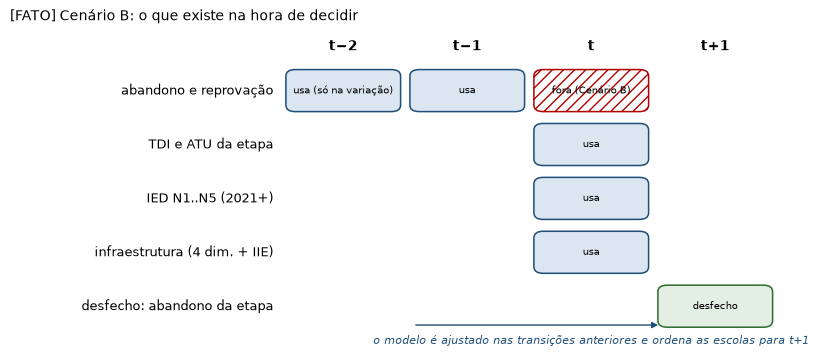

In [5]:
anos = ["t−2", "t−1", "t", "t+1"]
linhas_fig = [
    ("abandono e reprovação", {"t−2": "usa (só na variação)", "t−1": "usa", "t": "fora (Cenário B)", "t+1": ""}),
    ("TDI e ATU da etapa", {"t": "usa"}),
    ("IED N1..N5 (2021+)", {"t": "usa"}),
    ("infraestrutura (4 dim. + IIE)", {"t": "usa"}),
    ("desfecho: abandono da etapa", {"t+1": "desfecho"}),
]
estilo = {"usa": ("oficial", None), "usa (só na variação)": ("oficial", None), "fora (Cenário B)": ("bloqueado", "///"),
          "desfecho": ("avaliacao", None)}
fig, ax = plt.subplots(figsize=(10, 4.2))
D.tela(ax, 100, 60)
for j, a in enumerate(anos):
    ax.text(36 + j * 16 + 7, 56, a, ha="center", fontsize=10, fontweight="bold")
for i, (rotulo, celulas) in enumerate(linhas_fig):
    y = 45 - i * 10
    ax.text(34, y + 3.5, rotulo, ha="right", va="center", fontsize=9)
    for j, a in enumerate(anos):
        txt = celulas.get(a, "")
        if txt:
            est, hach = estilo[txt]
            D.caixa(ax, 36 + j * 16, y, 14, 7, txt, est, tamanho=7, negrito_primeira=False, hachura=hach)
ax.annotate("", xy=(36 + 3 * 16, 5), xytext=(36 + 1 * 16, 5),
            arrowprops={"arrowstyle": "-|>", "color": D.AZUL})
ax.text(36 + 2 * 16 + 7, 1.5, "o modelo é ajustado nas transições anteriores e ordena as escolas para t+1",
        ha="center", fontsize=8, color=D.AZUL, style="italic")
F.titulo(ax, "Cenário B: o que existe na hora de decidir", "FATO")
F.salvar(fig, FIGURAS, "03_cenario_b")
plt.show()

## 3. Regras que valem para tudo

As dez regras do `abandono-escolar/CLAUDE.md` §3:

| # | Regra | Por quê |
|---|---|---|
| 1 | `origem/`, `bruto/` e `externo/` são só leitura: escrita só em arquivo novo e conferido | a versão do INEP fica fixada pelo hash |
| 2 | nenhum dado versionado; só os hashes | os dados ficam fora do git |
| 3 | **nunca selecionar variável pela correlação com o desfecho** (exceção: o B1) | é sobreajuste; os blocos são escolhidos pelo que medem, antes de rodar |
| 4 | **nada de vazamento**: preditores de *t* → desfecho de *t*+1; toda transformação é ajustada só no treino | imputação e padronização dentro do `Pipeline` |
| 5 | **ausência estrutural nunca vira 0** | `'--'` é ausente; a escola sem a etapa em *t*+1 sai do painel |
| 6 | tipos explícitos: `CO_ENTIDADE` texto, `IN_`/`TP_` Int8, `QT_` Int32, taxas Float64 | código lido como número perde zeros e casa errado |
| 7 | não juntar em granularidade fina (turma, matrícula, docente) | a unidade é a escola |
| 8 | todo `merge` com `validate=` explícito e `how="left"` | uma duplicata não multiplica linhas em silêncio |
| 9 | **toda contagem publicada é gerada por código** | por isso estes notebooks só exibem |
| 10 | não inventar nome de coluna, código nem etapa | — |

E as regras do protocolo de 02/11/2026 (`DECISOES.md`):

- **Identidades contábeis (P026):** nunca aprovação, reprovação e abandono juntos (somam 100); IED só N1..N5
  (N6 = 100 − Σ, ALTO = N4+N5+N6).
- **Três formas de vazamento:**
  1. *temporal:* informação de *t*+1;
  2. *entre desfechos:* usar um `_T1` para prever outro;
  3. **reconstrução:** `DELTA1` + `LAG1` refaz o abandono de *t* e anularia o Cenário B; por isso a
     variação é a defasada.
- **Testes múltiplos:** famílias e K declarados antes do resultado; Holm dentro de cada família; um
  intervalo que exclui o zero mas não sobrevive ao Holm é mostrado e não decide nada.

# Parte B — Validação

## 4. Walk-forward com janela expansiva

Cada ano de teste é previsto por um modelo ajustado só com as transições anteriores. O primeiro desfecho do
painel é 2020, e o primeiro teste, 2021. A transição 2024→2025 é o **teste bloqueado** da D7: uma única
avaliação, depois de congelar tudo, só com `--incluir-2025` e autorização.

O protocolo nunca a usou: o `--incluir-2025` nunca foi passado. Mas ela não está intocada:

- os notebooks de outubro (smoke test, v1_old, v1 e v1_corrigido) e o Plano avançado de 07/10 testaram
  modelos nela;
- o desfecho de 2025 aparece em 5 análises descritivas.

O notebook 04 reúne esse histórico.

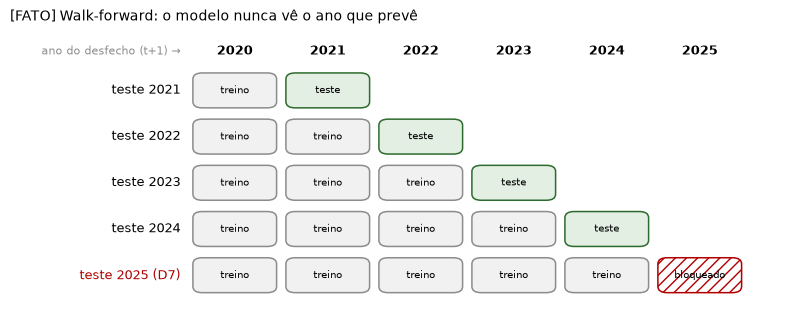

In [6]:
alvos = list(range(min(painel.ANOS_FEATURES) + 1, max(painel.ANOS_FEATURES) + 2))   # ANO_ALVO do painel
testes = list(walkforward.ANOS_TESTE) + [max(alvos)]
fig, ax = plt.subplots(figsize=(10, 3.6))
D.tela(ax, 100, 9 + 9 * len(testes))
for j, a in enumerate(alvos):
    ax.text(24 + j * 12 + 5, 9 * len(testes) + 4, str(a), ha="center", fontsize=9, fontweight="bold")
for i, teste in enumerate(testes):
    y = 9 * (len(testes) - 1 - i) + 3
    bloqueado = teste not in walkforward.ANOS_TESTE
    ax.text(22, y + 3, f"teste {teste}" + (" (D7)" if bloqueado else ""), ha="right", va="center", fontsize=9,
            color=D.VERMELHO if bloqueado else "black")
    for j, a in enumerate(alvos):
        if a < teste:
            D.caixa(ax, 24 + j * 12, y, 10, 6, "treino", "neutro", tamanho=7, negrito_primeira=False)
        elif a == teste:
            D.caixa(ax, 24 + j * 12, y, 10, 6, "bloqueado" if bloqueado else "teste",
                    "bloqueado" if bloqueado else "avaliacao", tamanho=7, negrito_primeira=False,
                    hachura="///" if bloqueado else None)
ax.text(22, 9 * len(testes) + 4, "ano do desfecho (t+1) →", ha="right", fontsize=8, color=D.CINZA)
F.titulo(ax, "Walk-forward: o modelo nunca vê o ano que prevê", "FATO")
F.salvar(fig, FIGURAS, "03_walk_forward")
plt.show()

- **Etapa 1** (só baselines): roda na série longa do `gustavo/`, com transições de 2008→2009 a 2023→2024. É
  possível porque os baselines não precisam de TDI, ATU nem IED.
- **Etapa 2** (modelos): só 2019–2024, onde existem as três fontes. A primeira dobra treina com uma só
  transição (2019→2020), cujo alvo de 2020 é ~71% zeros.
- **IED:** nos testes de 2021 e 2022, o treino não tem IED, porque o IED começa em 2021 como *t*. Só 2023 e
  2024 testam o IED (família F3).
- **O que não se faz:** escolher α, profundidade ou bloco olhando os anos de teste; usar 2025 dentro do
  walk-forward.

## 5. Baselines: a barra que todo modelo precisa passar

| Baseline | Previsão | Para quê |
|---|---|---|
| **B0** | média do desfecho nas transições anteriores | constante: o Recall@K dele é o do acaso, K/n |
| **B1** | o abandono de *t* da própria escola | persistência como valor (MAE, R²) |
| **B1R** | ordena as escolas pelo abandono de *t* | **limite superior otimista**: usa uma informação que não existe na hora de decidir |
| **B1R_lag** | ordena pelo abandono de *t*−1 | **a barra principal**: a mesma informação de rendimento que o Cenário B tem |
| **B2** | mediana do treino por localização × dependência | "território e rede": o que se faria sem dado da escola |

Resultado da Etapa 1, transições até 2023→2024 (notebook 03 do `abandono-escolar`):

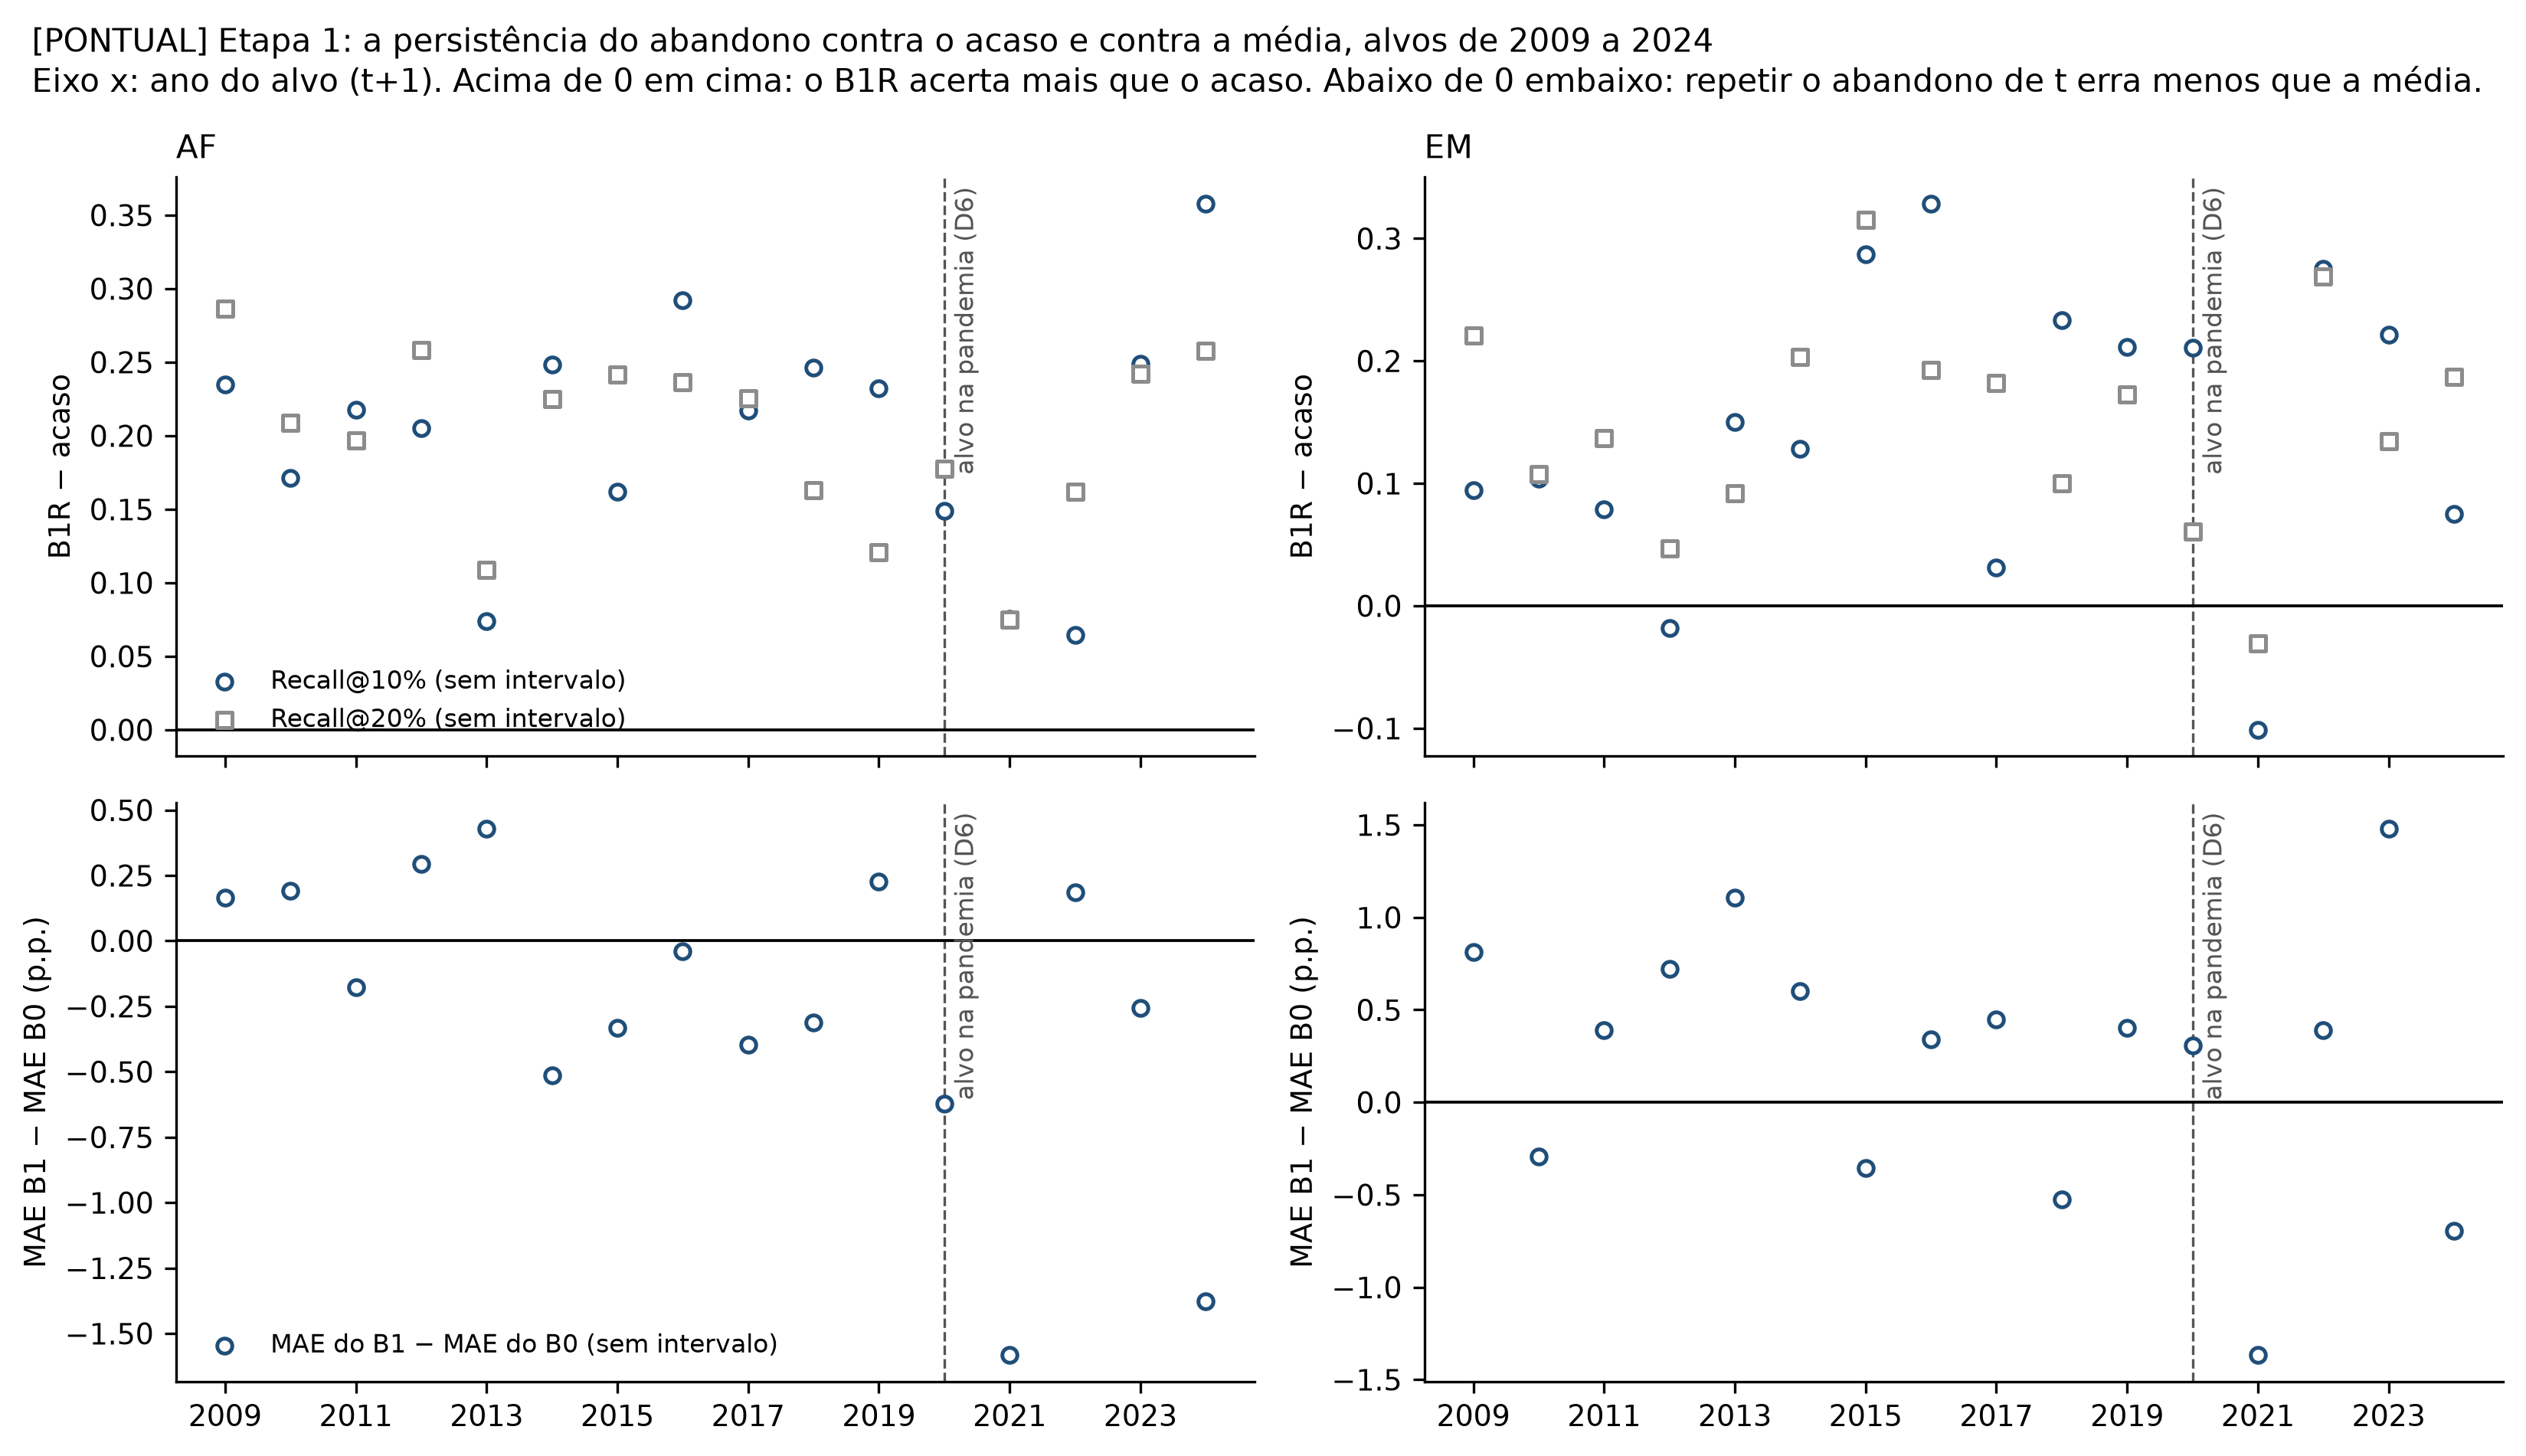

In [7]:
figura_existente(GUSTAVO / "saida" / "figuras" / "03_etapa1_baselines.png", largura=820)

**Leitura** [PONTUAL, sem intervalo]:

- **Como ordem, a persistência funciona:** o B1R fica acima do acaso no Recall@10% em 16 de 16 transições no
  AF e em 14 de 16 no EM.
- **Como valor, não funciona:** o B1 tem R² negativo em quase todas as transições e erra mais que a média em
  6 de 16 (AF) e 11 de 16 (EM).
- Por isso a métrica que decide é de ordem.

## 6. Modelos

- **Ridge** (α = 1, variáveis padronizadas) e **árvore de regressão** (profundidade 3, mínimo de 20 escolas por
  folha).
- Os hiperparâmetros são **fixos**, sem busca: com quatro anos de teste, ajustar seria escolher pelos dados
  de teste.
- A imputação (mediana + indicador de ausência) e a padronização ficam **dentro do `Pipeline`**, ajustadas
  só no treino de cada dobra. Assim ficam corrigidos dois dos quatro problemas do `v1.ipynb` (imputação
  antes do split, `fillna(0)`). Os outros dois deixaram de existir: o universo filtra as públicas, e não há
  variável categórica no modelo.
- Random Forest, boosting, GAM/EBM e a logística dos desfechos binários (B4) **não foram rodados**
  (síntese §5.4).

# Parte C — Métricas e incerteza

## 7. Recall@K

> Das K escolas que de fato tiveram o maior abandono em *t*+1, quantas a ordenação colocou entre as suas K
> primeiras?

$$\text{Recall@}K = \frac{|\text{TopK}(\hat y) \cap \text{TopK}(y)|}{K}, \qquad K = \text{round}(0{,}10\,n)\ \text{e}\ \text{round}(0{,}20\,n)$$

- *n* é o número de escolas do painel no ano: K ≈ 23–24 no AF e 16–17 no EM, para 10%.
- **Precision@K = Recall@K** por construção: os dois conjuntos têm K escolas.
- **Empates:** valor esperado sob desempate aleatório nos dois lados. O B0, constante, recebe exatamente K/n.
- **K = 30%** é só sensibilidade e fica fora da correção.
- **MAE, RMSE e R² descrevem e não decidem.** Com massa em zero e cauda longa, eles premiam acertar o zero;
  o uso real é escolher quais escolas visitar primeiro.

## 8. Incerteza: bootstrap por escola e Holm

- **Bootstrap por escola** (5.000 reamostragens na avaliação agrupada; IC 95% por percentis). Reamostra
  escolas, não linhas: a mesma escola aparece nos quatro anos de teste, e tratá-la como independente
  estreitaria o intervalo de forma falsa.
- **Famílias declaradas antes de rodar** (F1 a F5) e **correção de Holm** dentro de cada uma, no K primário.
  Os p ajustados estão no piso que B = 5.000 permite: são limites superiores.
- **Importância** = queda do Recall@K ao permutar um grupo inteiro de colunas (10 permutações, modelo do
  bloco 4). Mede o que o modelo **usa**, não o que acrescenta à persistência, nem causa.

**A propriedade que domina tudo** [FATO]: o intervalo de um ano tem largura ~0,30 no Recall@10%, tão largo
quanto a variação dos próprios dados. Agrupar as quatro transições reduz a largura em cerca de metade:

,grupo,item,valor
53,"largura IC 95% por ano (02b, modelos B)",AF Rec@10,0.30
54,"largura IC 95% por ano (02b, modelos B)",AF Rec@20,0.22
55,"largura IC 95% por ano (02b, modelos B)",EM Rec@10,0.31
56,"largura IC 95% por ano (02b, modelos B)",EM Rec@20,0.25
57,"largura IC 95% (02c, modelos B)",AF Rec@10 agrupado,0.16
58,"largura IC 95% (02c, modelos B)",AF Rec@10 por ano,0.31
59,"largura IC 95% (02c, modelos B)",AF Rec@20 agrupado,0.12
60,"largura IC 95% (02c, modelos B)",AF Rec@20 por ano,0.22
61,"largura IC 95% (02c, modelos B)",AF Rec@30 agrupado,0.10
62,"largura IC 95% (02c, modelos B)",AF Rec@30 por ano,0.18


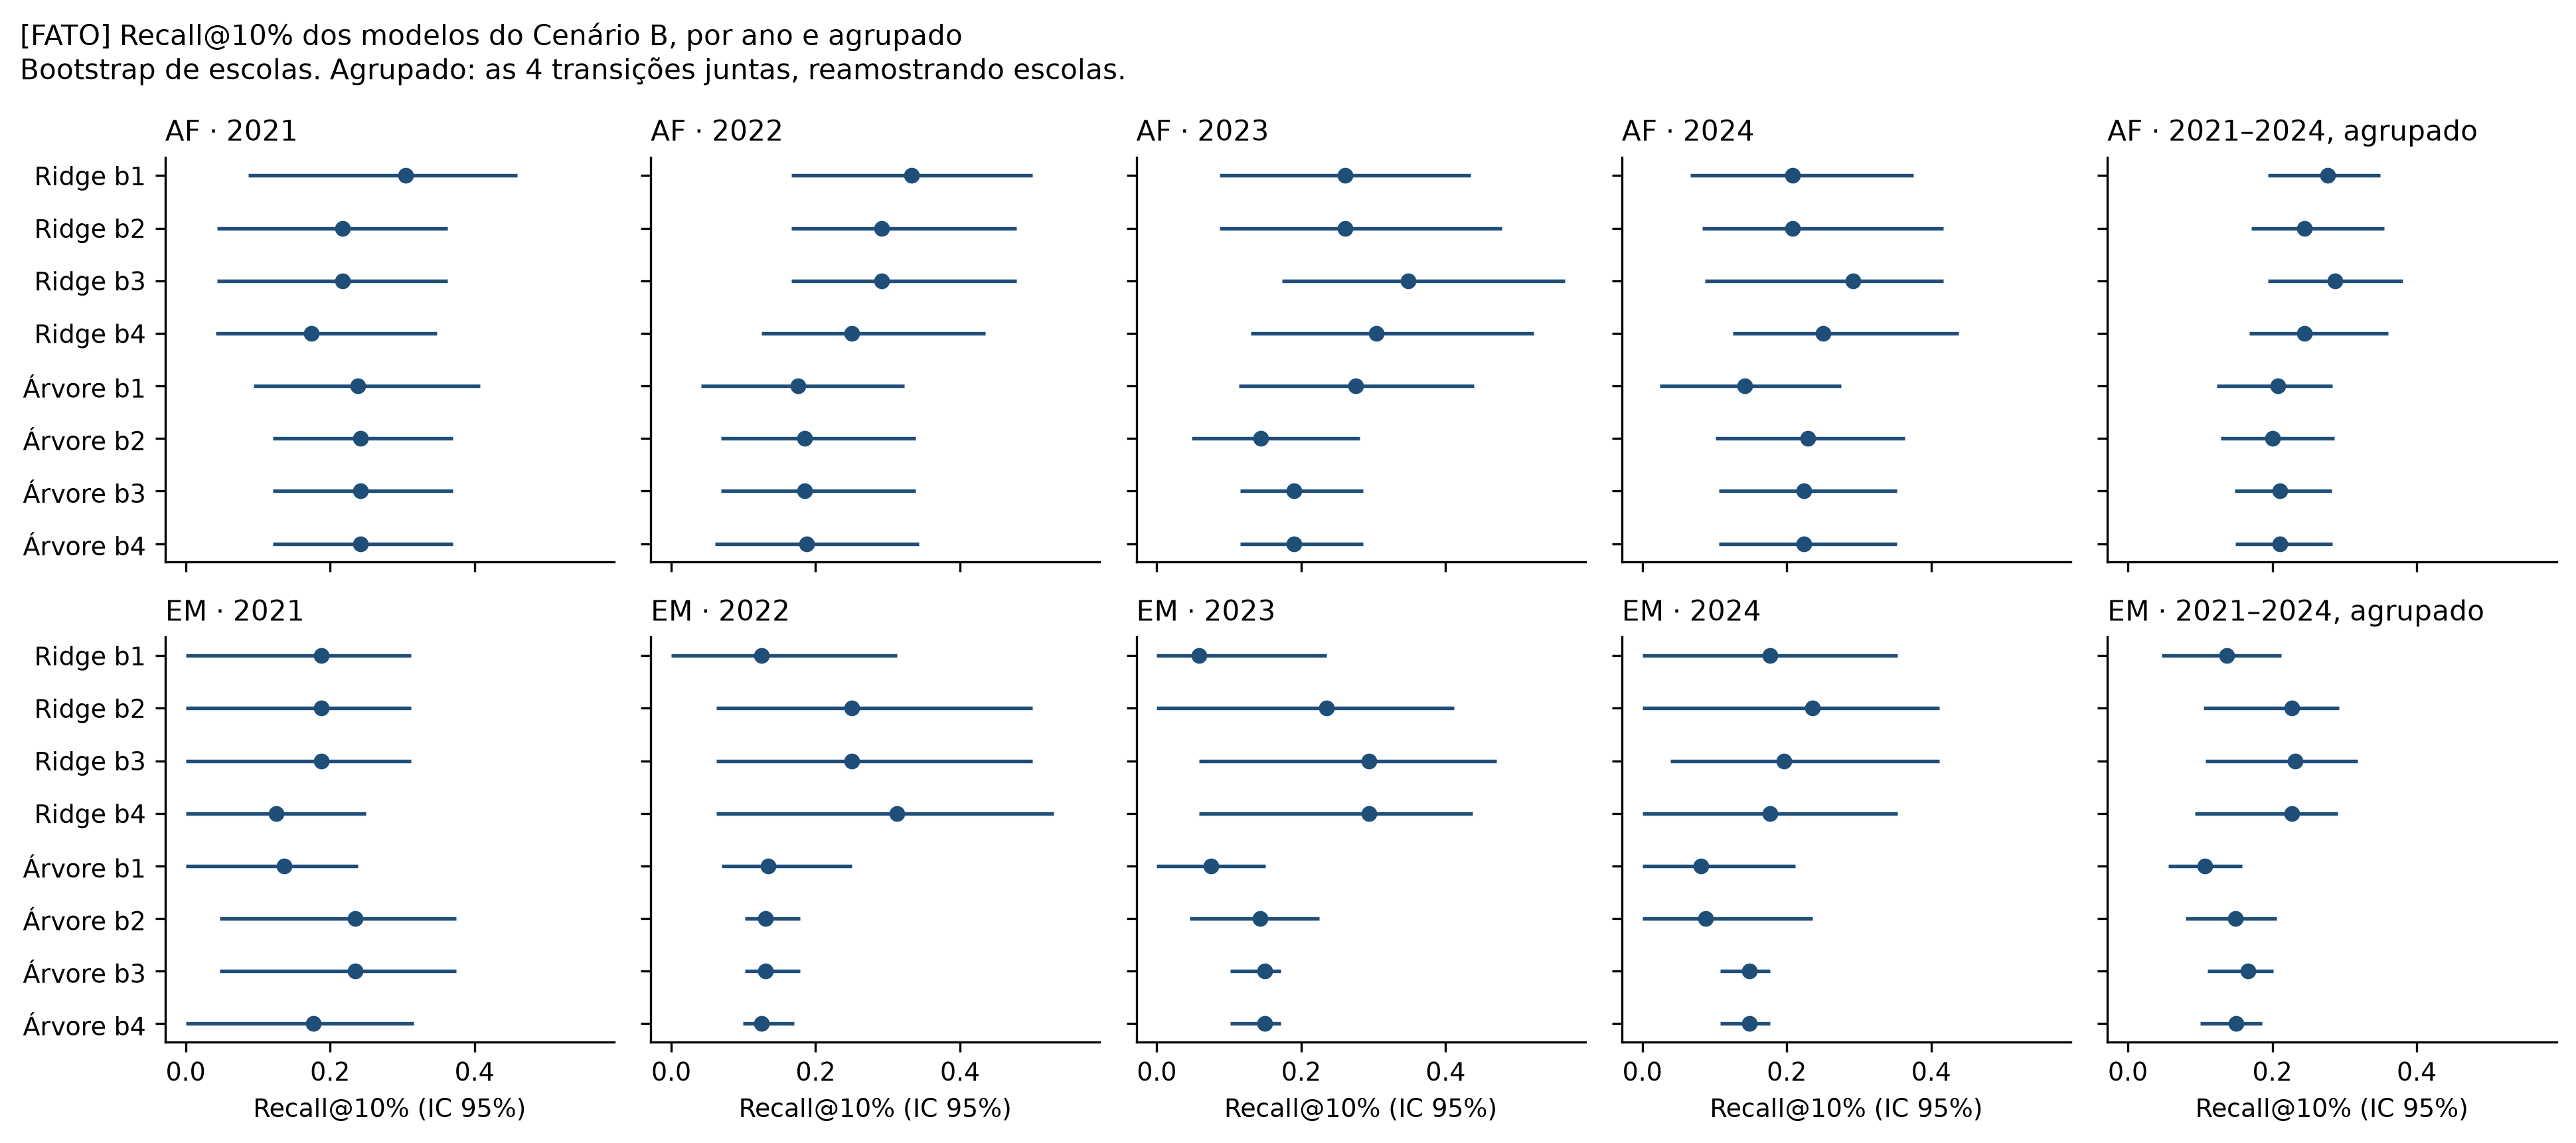

In [8]:
larg = sintese[sintese["grupo"].str.startswith("largura IC 95%")][["grupo", "item", "valor"]]
display(larg)
figura_existente(GUSTAVO / "saida" / "figuras" / "03_resolucao_recall10.png", largura=820)

## 9. O que o protocolo mediu

As figuras abaixo vêm do notebook `abandono-escolar/notebooks/03_avaliacao` e são o resumo visual da Etapa 2.
A primeira compara cada modelo com os baselines (diferença com intervalo e linha do zero). A segunda mostra
a importância de cada grupo de variáveis.

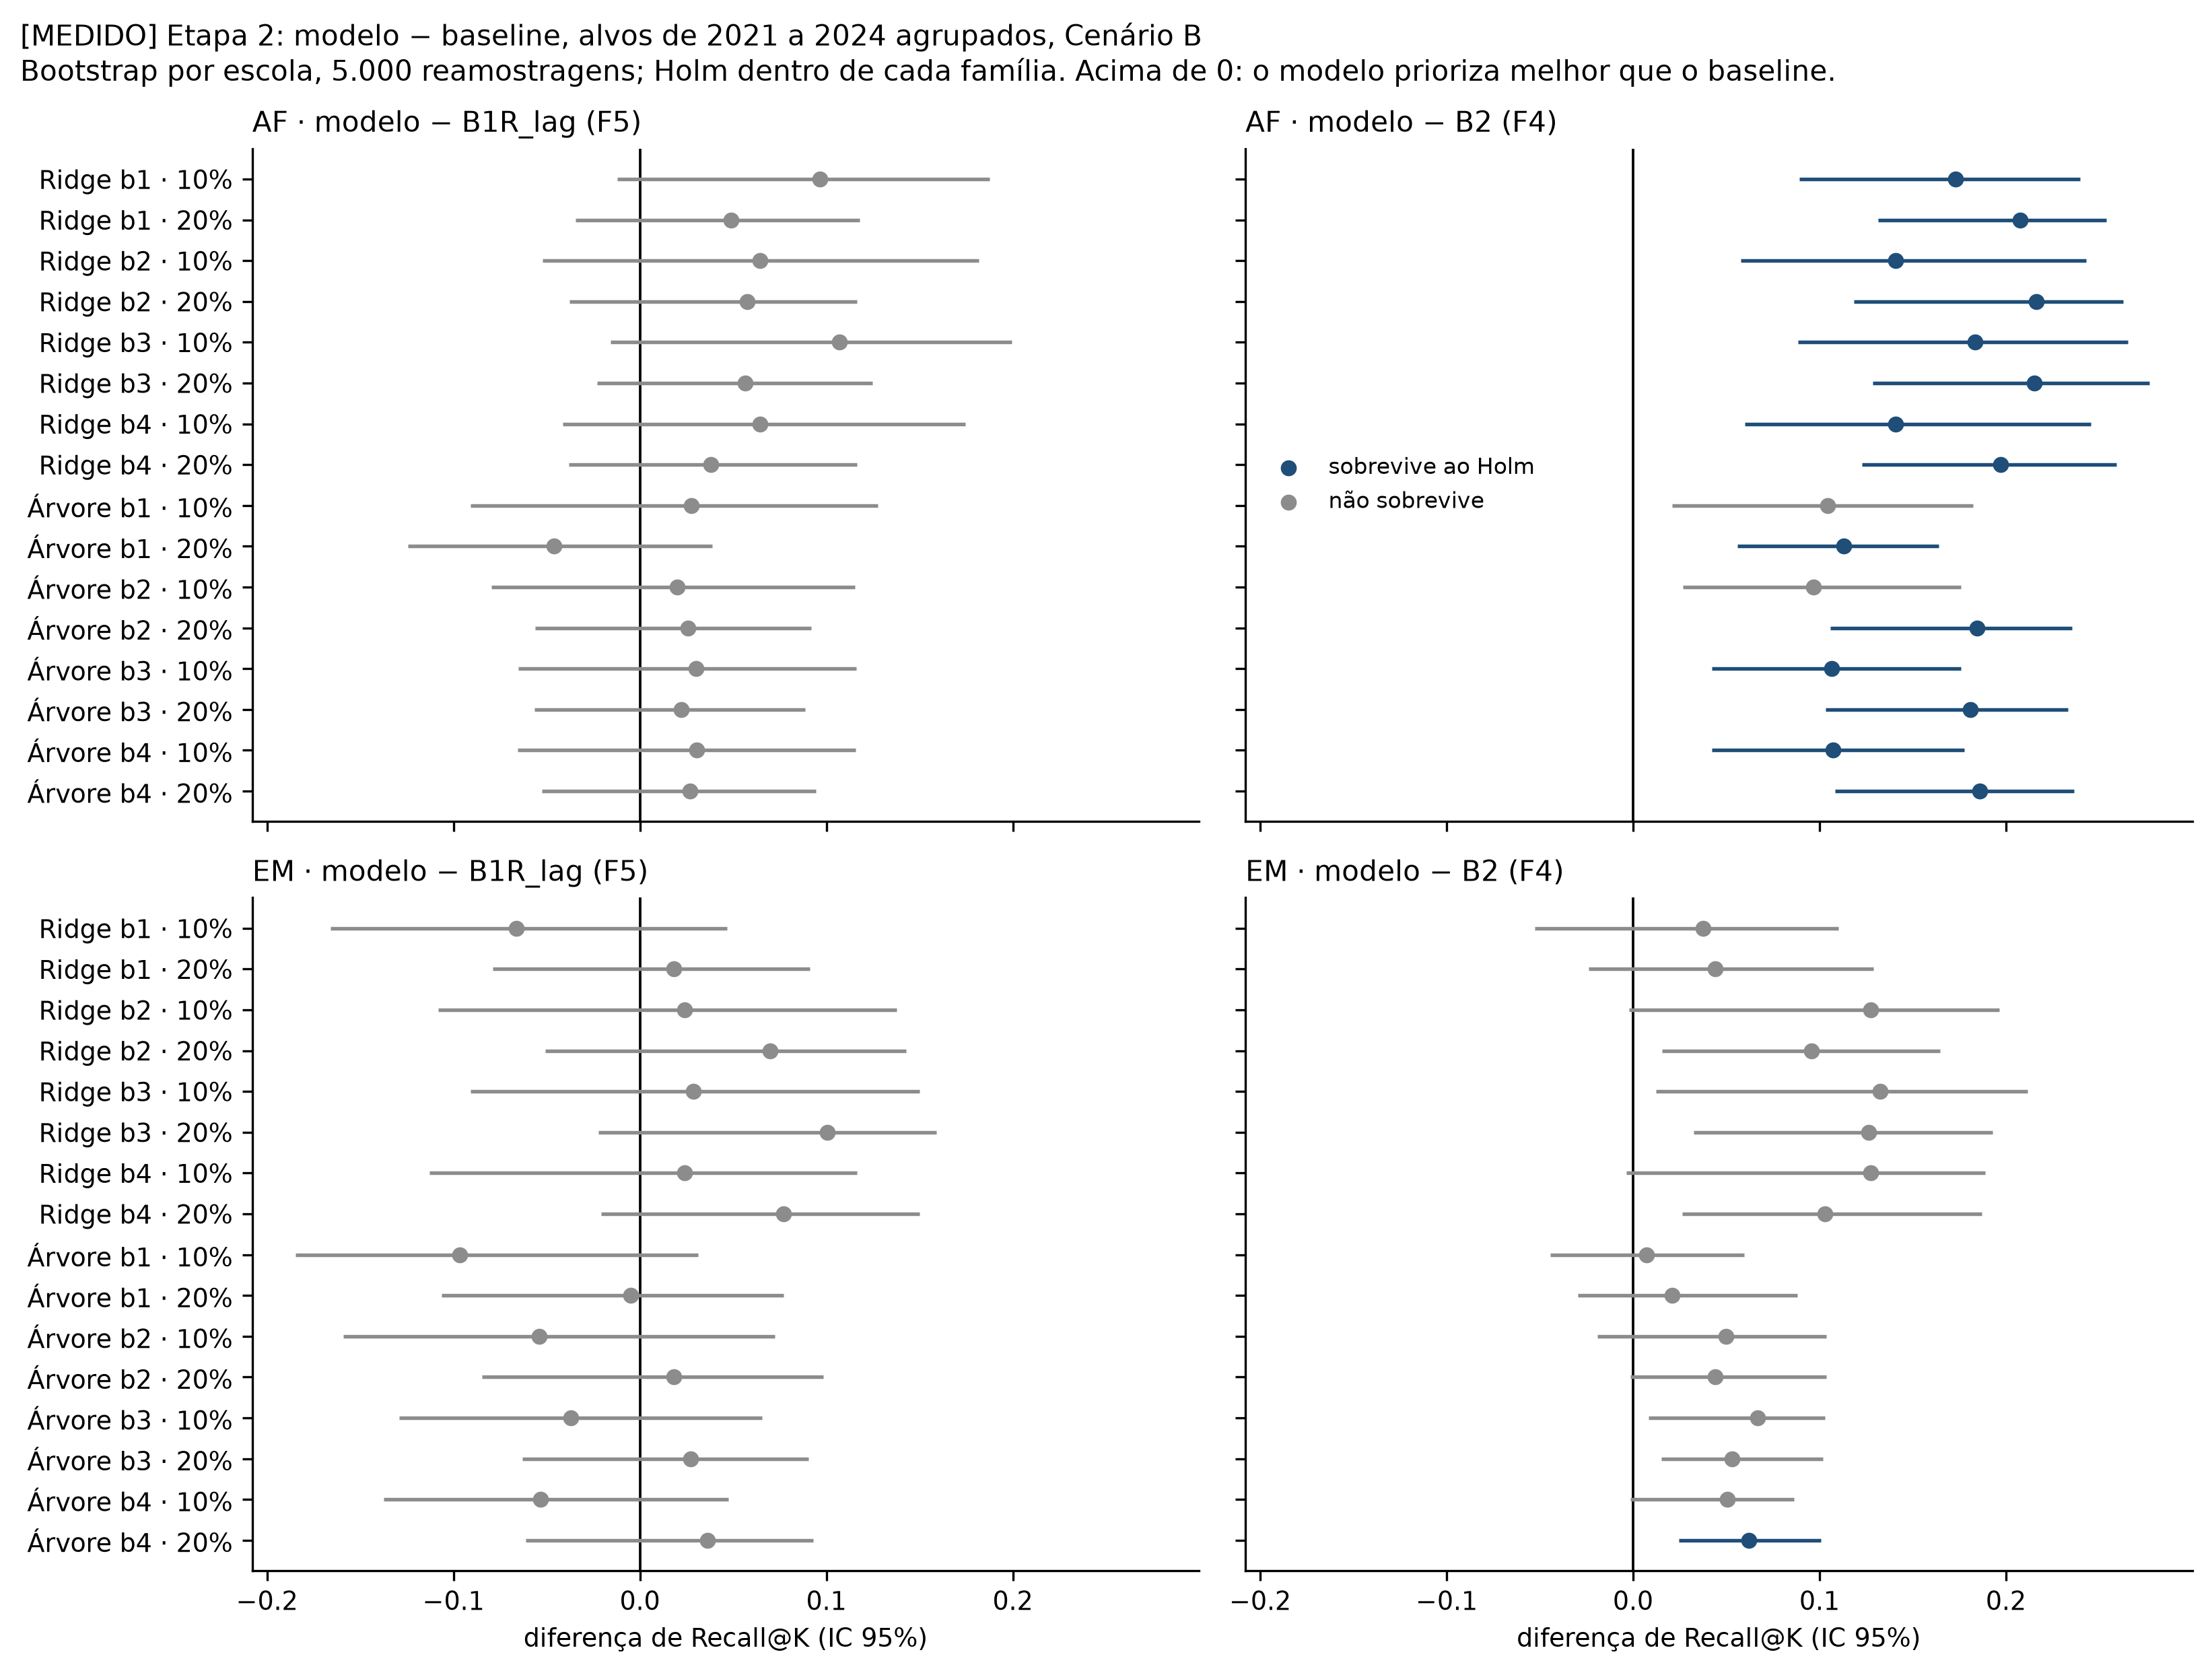

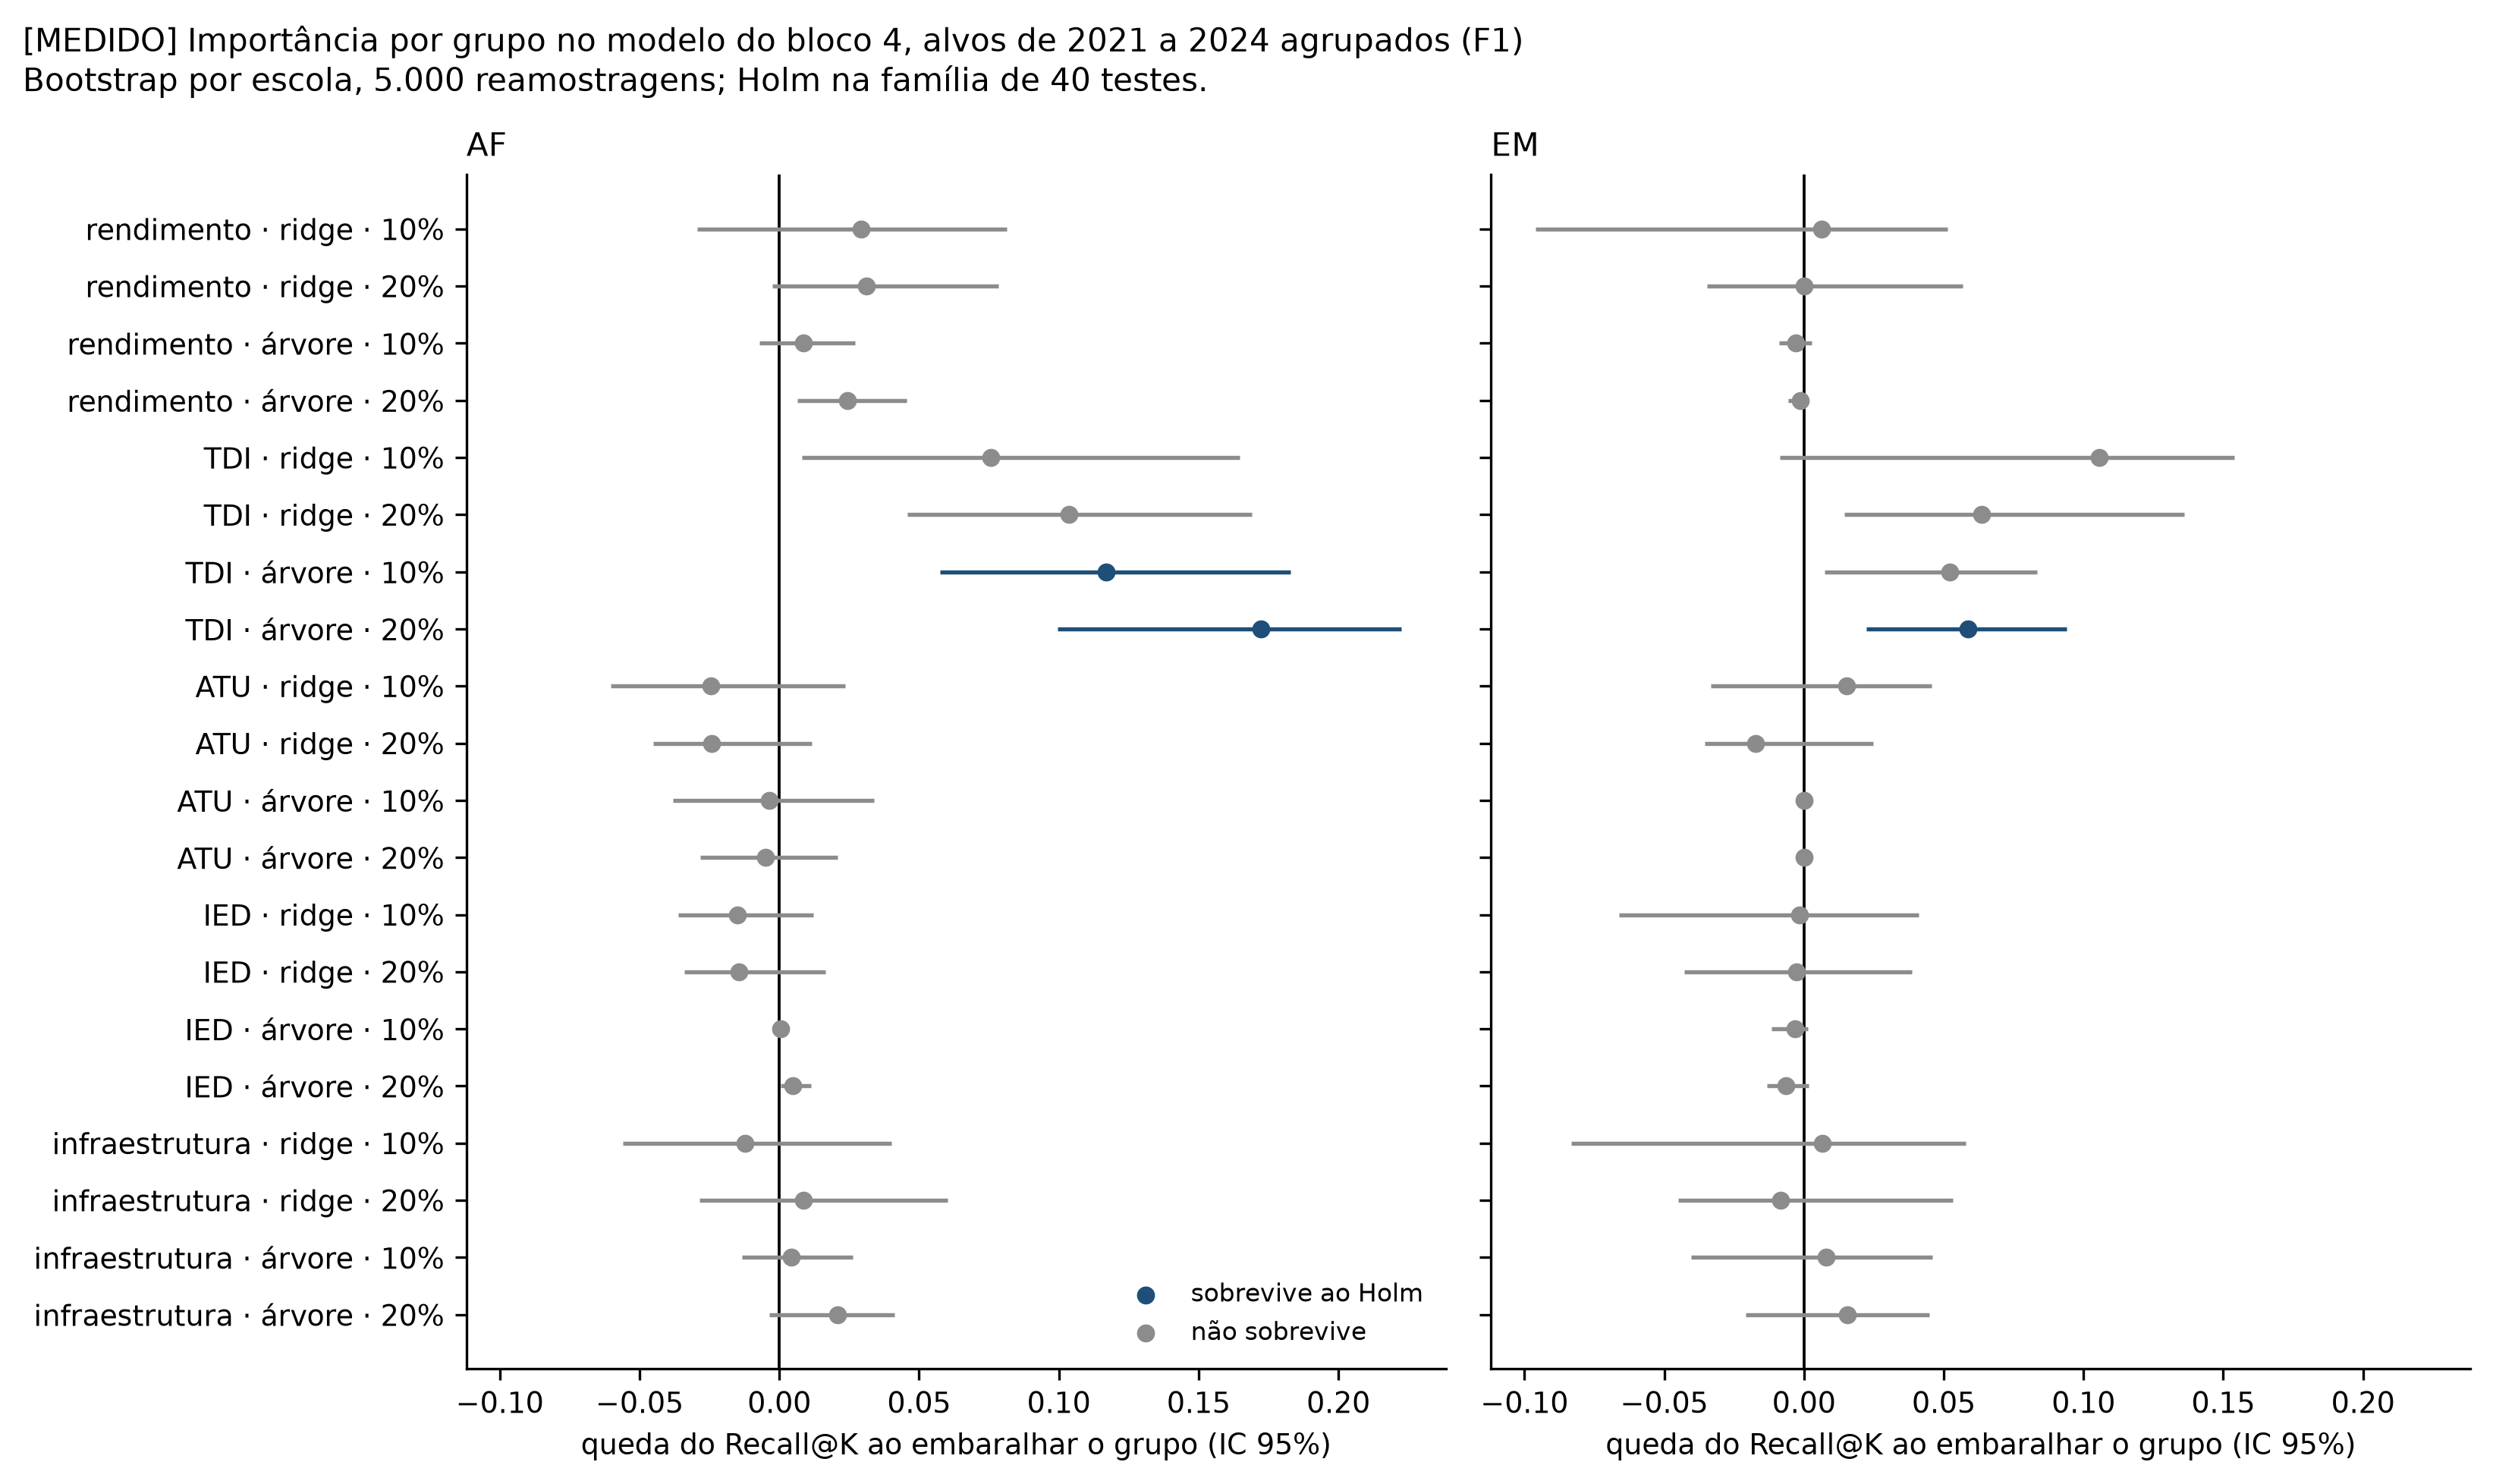

,familia,etapa,testes,sobrevivem,ic_exclui_zero_sem_correcao,pergunta
0,F1,AF,20,2,6,algum grupo tem importância > 0
1,F1,EM,20,1,3,algum grupo tem importância > 0
2,F2,AF,8,5,7,TDI separável do rendimento e do ATU
3,F2,EM,8,2,7,TDI separável do rendimento e do ATU
4,F3,AF,4,0,1,IED > 0 (2023–2024)
5,F3,EM,4,0,0,IED > 0 (2023–2024)
6,F4,AF,16,14,16,modelo supera B2
7,F4,EM,16,1,7,modelo supera B2
8,F5,AF,28,0,0,"modelo supera B1R_lag, ou bloco k > k−1"
9,F5,EM,28,0,0,"modelo supera B1R_lag, ou bloco k > k−1"


In [9]:
figura_existente(GUSTAVO / "saida" / "figuras" / "03_modelo_menos_baseline.png", largura=820)
figura_existente(GUSTAVO / "saida" / "figuras" / "03_importancia_grupos.png", largura=820)
display(familias.assign(pergunta=familias["familia"].map({
    "F1": "algum grupo tem importância > 0", "F2": "TDI separável do rendimento e do ATU",
    "F3": "IED > 0 (2023–2024)", "F4": "modelo supera B2", "F5": "modelo supera B1R_lag, ou bloco k > k−1"})))

**Em uma linha por resultado** (síntese §3):

| Nível | Resultado |
|---|---|
| [FATO] | o instrumento, como está, **não separa os blocos entre si nem o modelo da persistência defasada**: largura ~0,30 por ano |
| [MEDIDO] | no AF, os 8 modelos ordenam melhor que território × rede (B2); no EM, 1 de 16 |
| [MEDIDO] | a árvore depende do TDI, de forma separável do rendimento e do ATU (AF nos dois K; EM no de 20%) |
| [MEDIDO, nulo] | nenhum modelo supera o B1R_lag; nenhum bloco supera o anterior (F5: 0 de 56) |
| [MEDIDO, nulo] | rendimento de *t*−1, ATU, IED e infraestrutura: 0 de 8 testes cada na F1 |
| [PONTUAL] | Cenário A não superou o B no Ridge do bloco 1 (sem intervalo) |

**O que isso significa para o método.** O próximo passo não é acrescentar variáveis: a Fase 3 está
suspensa. O que falta é **poder estatístico**. Há três caminhos que já constam dos documentos, todos dependentes de decisão:

1. **mais transições:** a extensão D11 para 2007–2018, com TDI e ATU desses anos baixados e registrados;
2. **avaliação agrupada com outros desenhos:** por exemplo, group k-fold por escola (nunca rodado);
3. **as sensibilidades S1–S4 da D6.**

O teste 2024→2025 só deve ser aberto depois disso, uma única vez.